# Analysis of Rental Prices in Berlin

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as sps
import statsmodels.formula.api as smf
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [2]:
rentals = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "sergionefedov/berlin-real-estate-sales-and-rentals-2020-2026",
    "rentals.csv"
)

rentals["date_listed"] = pd.to_datetime(rentals["date_listed"])

# 1. Introduction

This project analyzes the factors that affect rental prices in Berlin.

The analysis is based on the **rentals.csv** dataset from 
[Berlin Real Estate: Sales & Rentals 2020-2026 on Kaggle](https://www.kaggle.com/datasets/sergionefedov/berlin-real-estate-sales-and-rentals-2020-2026/data), containing 30,000 rental listings.

The objective of this project is to answer the following research question: 

> *Which rental characteristics and locations are associated with higher cold rent prices in Berlin?*



Throughout this project, the term **rental price** refers to the **cold rent per square meter** (```rent_per_m2_kalt```), unless stated otherwise. 

This choice was made because it enables a fair comparison between rental-properties of different sizes and is not affected by operating costs that may vary depending on individual consumption, such as heating or water usage.

# 2. Dataset Overview 


Before performing any analysis, we inspect the dataset to understand its structure and detect potential data quality issues.

## 2.1. General Overview and Data Quality

In [3]:
rentals.head()

,id,date_listed,ortsteil,bezirk,kiez_premium,lat,lon,property_type,rooms,area_m2,...,transit_line,transit_distance_min,to_brandenburg_gate_km,kaltmiete_eur_monthly,nebenkosten_eur_monthly,warmmiete_eur_monthly,rent_per_m2_kalt_eur,rent_includes_warmmiete,kaution_months,warmmiete_eur_monthly_usd
0,R000001,2023-12-18,Adlershof,Treptow-Köpenick,medium,52.44391,13.53835,2_room,2,55.1,...,U7,203,13.53,517,281,798,9.37,False,3,861
1,R000002,2021-06-07,Lankwitz,Steglitz-Zehlendorf,medium,52.44035,13.33848,4_room,4,106.6,...,U8,111,8.85,1281,347,1628,12.03,True,3,1758
2,R000003,2022-08-19,Britz,Neukölln,low,52.44825,13.45215,3_room,3,102.5,...,U7,27,9.09,1366,524,1889,13.32,False,1,2041
3,R000004,2025-12-29,Hellersdorf,Marzahn-Hellersdorf,low,52.53063,13.62405,3_room,3,90.5,...,S Ringbahn,167,16.74,469,335,804,5.18,True,2,869
4,R000005,2022-07-18,Wartenberg,Lichtenberg,low,52.58212,13.50497,2_room,2,55.6,...,S Ringbahn,110,11.30,369,260,629,6.64,False,2,679


In [4]:
rentals.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   id                         30000 non-null  str           
 1   date_listed                30000 non-null  datetime64[us]
 2   ortsteil                   30000 non-null  str           
 3   bezirk                     30000 non-null  str           
 4   kiez_premium               30000 non-null  str           
 5   lat                        30000 non-null  float64       
 6   lon                        30000 non-null  float64       
 7   property_type              30000 non-null  str           
 8   rooms                      30000 non-null  int64         
 9   area_m2                    30000 non-null  float64       
 10  floor                      30000 non-null  int64         
 11  total_floors               30000 non-null  int64         
 12  building_era   

In [5]:
rentals.describe()

,date_listed,lat,lon,rooms,area_m2,floor,total_floors,transit_distance_min,to_brandenburg_gate_km,kaltmiete_eur_monthly,nebenkosten_eur_monthly,warmmiete_eur_monthly,rent_per_m2_kalt_eur,kaution_months,warmmiete_eur_monthly_usd
count,30000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,2023-03-02 20:33:44.640000,52.512407,13.390837,2.522667,75.587640,2.479367,4.951267,89.227100,10.106720,946.804133,265.886900,1212.689167,12.123417,2.500200,1309.704800
min,2020-01-01 00:00:00,52.357930,13.113280,1.000000,20.000000,0.000000,3.000000,0.000000,0.230000,86.000000,50.000000,148.000000,2.550000,1.000000,160.000000
25%,2021-08-06 18:00:00,52.461430,13.299788,2.000000,48.400000,1.000000,4.000000,27.000000,6.650000,458.000000,164.000000,643.000000,8.180000,2.000000,694.000000
50%,2023-03-05 00:00:00,52.511570,13.386030,2.000000,68.700000,2.000000,5.000000,75.000000,9.690000,735.000000,237.000000,988.000000,10.780000,3.000000,1067.000000
75%,2024-09-22 06:00:00,52.563122,13.480293,3.000000,94.100000,4.000000,6.000000,137.000000,13.210000,1203.000000,332.000000,1532.000000,14.800000,3.000000,1655.000000
max,2026-04-29 00:00:00,52.658910,13.707070,5.000000,302.300000,8.000000,8.000000,424.000000,26.090000,7624.000000,1305.000000,8685.000000,46.400000,3.000000,9380.000000
std,NaN,0.063742,0.125544,1.132488,37.465641,1.864499,1.384494,72.848119,4.612213,724.030300,142.681064,829.216366,5.483438,0.669588,895.554965


In [6]:
print(f"The Dataset contains {rentals.isna().sum().sum()} missing values and {rentals.duplicated().sum()} duplicated observations.")

The Dataset contains 0 missing values and 0 duplicated observations.


There are no missing values or duplicated observations in the dataset. Therefore, no imputation or duplicate removal is required.

## 2.2. Numeric Variables: Overview 

To obtain an initial insight, histograms of the numerical variables are plotted. This allows us to detect skewness and potential outliers.

The histograms reveal several characteristics of the dataset: 

- Most continuous variables, including the rental price (```rent_per_m2_kalt_eur```), are right-skewed.

- The rental price variable contains a small number of extreme observations.

- The geographic coordinates (```lat``` and ```lon```) are, as expected, concentrated within the Berlin metropolitan area (*52° 31' N latitude and 13° 23' E longitude*)


The skewness and extreme values suggest that some variables may require further investigation before the inferential analysis.


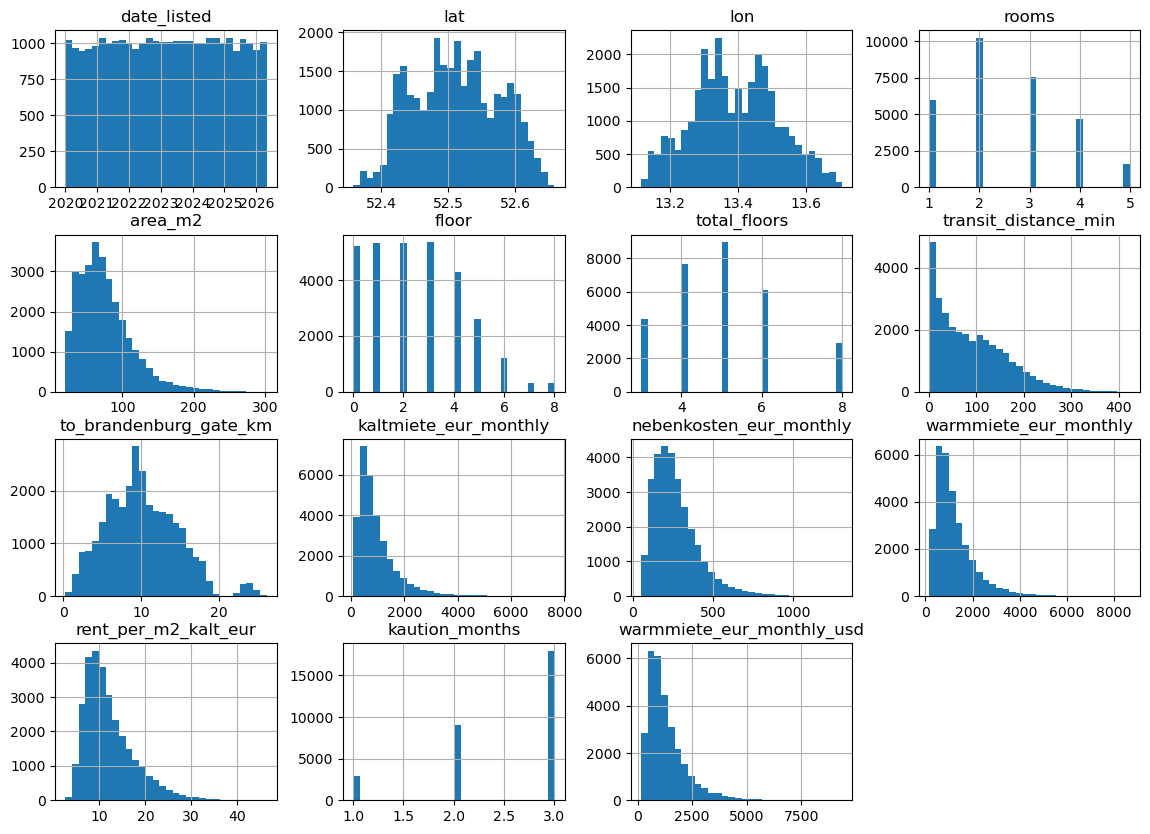

In [7]:
rentals.hist(figsize = (14, 10), bins = 30)
plt.show()

## 2.3. Categorical Variables: Overview

The dataset also includes several categorical variables describing apartment characteristics and location, such as the district (`bezirk`), balcony availability (`balcony`) and the `kiez_premium` category. The latter groups neighborhoods into three ordered categories representing their overall attractiveness and perceived quality of living.

Some categorical variables appear to be closely related to other numerical or categorical variables. These relationships will be explored further in the subsequent analysis.

In [8]:
rentals.select_dtypes(include = ["bool", "str", "object"]).describe()

,id,ortsteil,bezirk,kiez_premium,property_type,building_era,energy_class,position,condition,has_lift,has_balcony,furnished,transit_station,transit_line,rent_includes_warmmiete
count,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000
unique,30000,82,12,3,5,4,9,4,5,2,2,2,135,7,2
top,R000001,Pankow (Ort),Reinickendorf,medium,2_room,post_war_1949_1990,E,vorderhaus,modernisiert,False,True,False,Wittenau U,U7,False
freq,1,420,4124,12332,10218,12706,5548,16637,9046,16523,17883,23930,597,7995,18053


# 3. Descriptive Analysis

This section explores the distribution of rental prices and investigates how they are associated with selected apartment characteristics using descriptive statistics and visualizations.

1. Distribution of Rental prices (`rent_per_m2_kalt_eur`)
2. Rental prices across categorical variables
3. Relationships between numerical variables and rental prices

## 3.1. Distribution of Rental Prices

The rental prices range from $2.55/m^2$ to $46.40/m^2$, indicating a large variation across the market.

Furthermore the mean exceeds the median, indicating a right-skewed distribution confirming our observation in Section **2.2.**

We can therefore conclude: 

> While most rental properties are offered at relatively moderate rental prices, there is a relatively small number of high-priced listings increasing the average.

In [9]:
rentals[["rent_per_m2_kalt_eur"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rent_per_m2_kalt_eur,30000.0,12.123417,5.483438,2.55,8.18,10.78,14.8,46.4


To further illustrate this observation, we visualize the distribution of rental prices using a histogram. 
The mean, median and a kernel density estimate (KDE) are added to provide a smoother visualization of the underlying distribution.

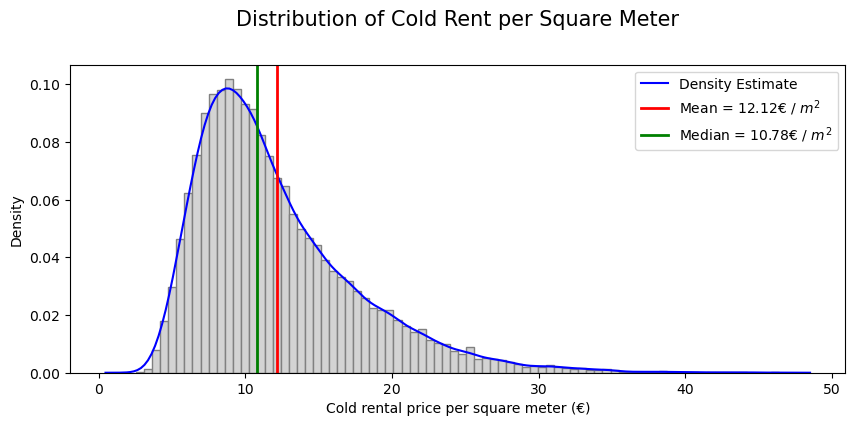

In [10]:
fig, ax = plt.subplots(figsize = (10,4))

ax.hist(rentals["rent_per_m2_kalt_eur"], bins = 80, color = "lightgray", density = True, edgecolor = "gray")
sns.kdeplot(data = rentals, x = "rent_per_m2_kalt_eur", ax = ax, label = "Density Estimate", color = "blue")
ax.axvline(rentals["rent_per_m2_kalt_eur"].mean(), color = "red", label = "Mean = 12.12€ / $m^2$", lw = 2)
ax.axvline(rentals["rent_per_m2_kalt_eur"].median(), color = "green", label = "Median = 10.78€ / $m^2$", lw = 2)
ax.set_title("Distribution of Cold Rent per Square Meter", size = 15, y = 1.1)
ax.set_xlabel("Cold rental price per square meter (€)")
plt.legend()
plt.show()

## 3.2 Rental Prices Across Categorical Variables

To investigate the association between categorical rental property characteristics and rental prices, we compare the distribution of rental prices across the different categories.

We begin by obtaining an overview of all categorical variables:

In [11]:
rentals.select_dtypes(include = ["str", "bool", "object", "category"]).head()

,id,ortsteil,bezirk,kiez_premium,property_type,building_era,energy_class,position,condition,has_lift,has_balcony,furnished,transit_station,transit_line,rent_includes_warmmiete
0,R000001,Adlershof,Treptow-Köpenick,medium,2_room,post_war_1949_1990,E,vorderhaus,kernsaniert,False,True,False,Konstanzer Straße,U7,False
1,R000002,Lankwitz,Steglitz-Zehlendorf,medium,4_room,modern_1990_2010,E,vorderhaus,saniert,True,False,False,Heinrich-Heine-Straße,U8,True
2,R000003,Britz,Neukölln,low,3_room,modern_1990_2010,C,vorderhaus,saniert,True,False,False,Neukölln,U7,False
3,R000004,Hellersdorf,Marzahn-Hellersdorf,low,3_room,altbau_pre_1949,G,seitenflügel,kernsaniert,True,False,False,Neukölln S,S Ringbahn,True
4,R000005,Wartenberg,Lichtenberg,low,2_room,modern_1990_2010,H,vorderhaus,modernisiert,True,True,False,Gesundbrunnen S,S Ringbahn,False


### 3.2.1. Location

As location is generally considered an important factor influencing rental prices, we begin by examining the district (`bezirk`)


Firstly, we examine the distribution of rental listings across Berlin districts to identify potential under- or overrepresentation.

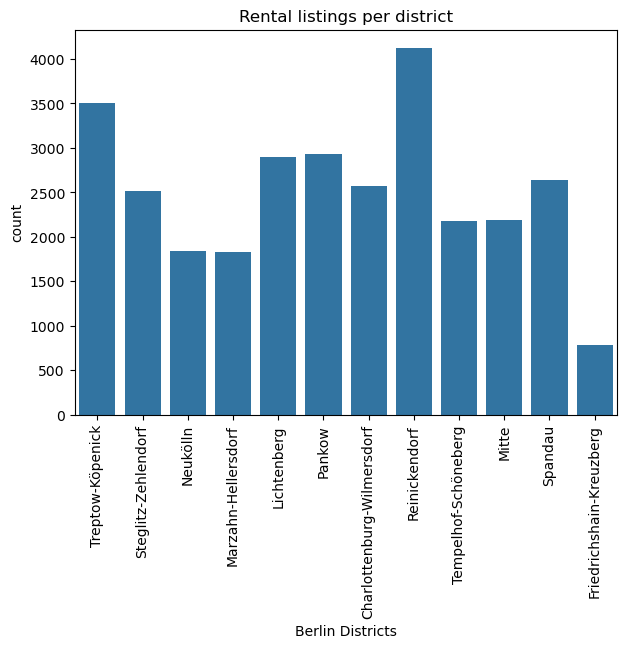

In [12]:
fig, ax = plt.subplots(figsize = (7,5))

sns.countplot(data = rentals, x = "bezirk", ax = ax)
plt.xticks(rotation = 90)
plt.title("Rental listings per district")
ax.set_xlabel("Berlin Districts")
plt.show()

- *Reinickendorf* contains the largest number of rental listings
- *Treptow-Köpenick* is also strongly represented while *Friedrichshain-Kreuzberg* is comparatively less represented.

All districts are represented but the number of listings varies considerably. This should be taken into account when interpreting the following comparison of rental prices across districts.

To investigate whether rental prices differ across Berlin districts, we compare their distributions using a box plot.

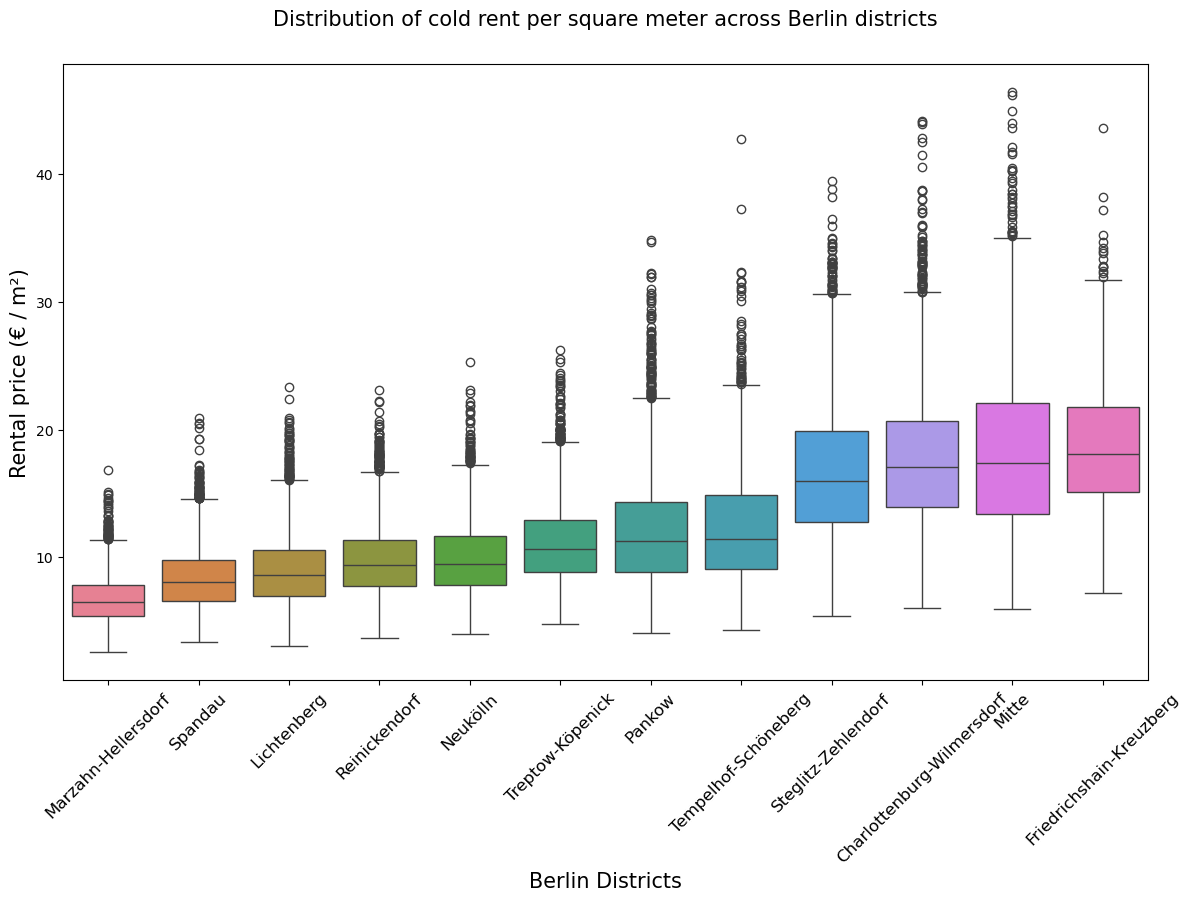

In [13]:
fig, ax = plt.subplots(figsize = (14, 8))

order = (rentals.groupby("bezirk")["rent_per_m2_kalt_eur"].median().sort_values().index)

sns.boxplot(ax = ax, data = rentals, x = "bezirk", y = "rent_per_m2_kalt_eur", hue = "bezirk", order = order, hue_order=order)
ax.set_ylabel("Rental price (€ / m²)", size = 15)
ax.set_xlabel("Berlin Districts", size=15)
plt.xticks(rotation = 45, size = 12)
ax.set_title("Distribution of cold rent per square meter across Berlin districts", size = 15, y = 1.05)
plt.show()

The box plot reveals clear differences in the distribution of rental prices across Berlin districts.

- *Marzahn* has both the lowest median rental price and the lowest observed rental price.
- *Mitte* exhibits the widest range of rental prices and contains the highest observed rental price.
- *Friedrichshain-Kreuzberg* has the highest median rental price.

These findings suggest that district is an important factor associated with rental prices and motivate further inferential analysis.

Because the districts are represented by different sample sizes, we compute bootstrap confidence intervals for the median rental price of each district to support the interpretation of the box plots.

In [14]:
np.random.seed(2026)
def bootstrap_ci(data: np.ndarray, bootnum: int = 10000):
    boot_medians = []

    for _ in range(bootnum):
        sample = np.random.choice(data, size=len(data), replace=True)
        boot_medians.append(np.median(sample))

    return np.percentile(boot_medians, [2.5, 97.5])

ci_districts = []

for district, group in rentals.groupby("bezirk"):
    median = np.median(group["rent_per_m2_kalt_eur"])
    lower, upper = bootstrap_ci(group["rent_per_m2_kalt_eur"].values)

    ci_districts.append({
        "District": district,
        "Median": median,
        "CI Lower": lower,
        "CI Upper": upper
    })

ci_df = pd.DataFrame(ci_districts)

In [15]:
ci_df

,District,Median,CI Lower,CI Upper
0,Charlottenburg-Wilmersdorf,17.030,16.810,17.290
1,Friedrichshain-Kreuzberg,18.075,17.605,18.645
2,Lichtenberg,8.570,8.440,8.680
3,Marzahn-Hellersdorf,6.510,6.400,6.610
4,Mitte,17.405,17.050,17.715
5,Neukölln,9.480,9.315,9.670
6,Pankow,11.260,11.110,11.450
7,Reinickendorf,9.410,9.325,9.520
8,Spandau,8.060,7.940,8.170
9,Steglitz-Zehlendorf,16.000,15.775,16.320


After bootstrapping the median rental price of each district using 10,000 resamples, the resulting confidence intervals are relatively narrow, indicating that the estimated district medians are precise and supporting the interpretation of the box plots.

### 3.2.2. Amenities

As amenities such as a balcony, a lift, or furniture are expected to affect the attractiveness of a rental property, we examine how rental prices vary depending on the presence of these amenities.

We again use a box plot to compare the distribution of rental prices for properties with and without these amenities.

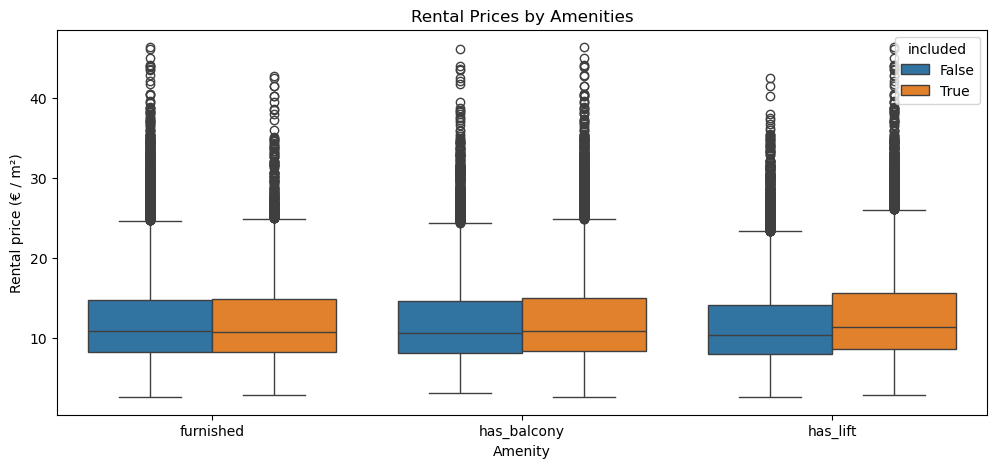

In [16]:
fig, ax = plt.subplots(figsize = (12,5))

amenities = ["furnished", "has_balcony", "has_lift"]

amenities = rentals.melt(
    id_vars="rent_per_m2_kalt_eur",
    value_vars=amenities,
    var_name="amenity",
    value_name="included"
)

sns.boxplot(
    data=amenities,
    x="amenity",
    y="rent_per_m2_kalt_eur",
    hue="included",
    ax = ax
)
plt.xlabel("Amenity")
plt.ylabel("Rental price (€ / m²)")
plt.title("Rental Prices by Amenities")
plt.show()

Surprisingly, there is little to no difference in the median rental price between furnished and unfurnished rental properties. Rental properties that are not furnished exhibit a wider range of rental prices and more extreme observations. This suggests that factors correlated with furnishing, rather than furnishing itself, may be associated with higher rental prices.

Regarding balconies, properties with a balcony exhibit a slightly higher median rental price than those without one.

The presence of a lift appears to have the strongest association with rental prices. Properties with a lift show a higher median rental price and include more of the highest-priced listings.


Compared to the differences observed across districts, the selected amenities exhibit only minor differences in rental prices. This suggests that location may be a stronger factor associated with rental prices than the presence of individual amenities.''

### 3.2.3. Condition

Generally, the condition of a rental property can be expected to influence its attractiveness to potential tenants. In this subsection, we descriptively analyze the association between property condition and rental prices.

We again use a box plot to gain an initial insight into the distribution of rental prices across the different property conditions.


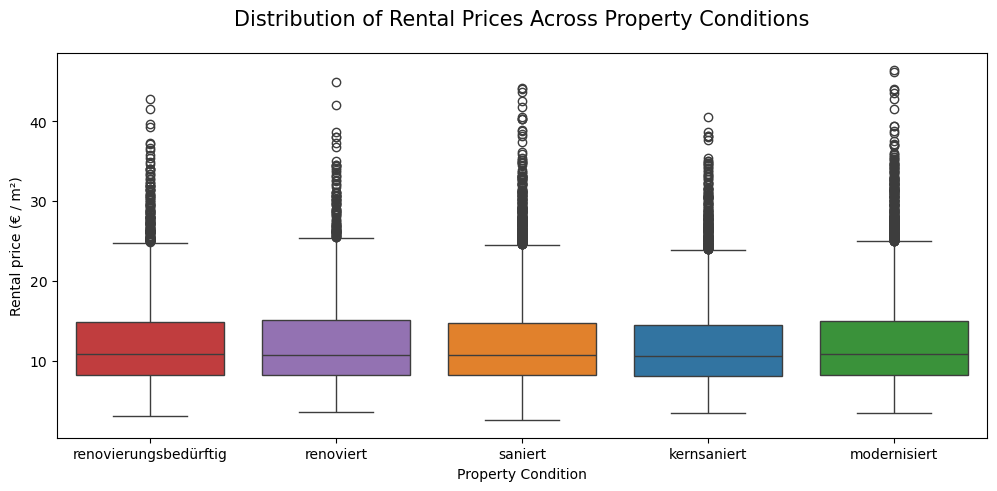

,condition_rent_median
condition,
kernsaniert,10.65
modernisiert,10.86
renoviert,10.78
renovierungsbedürftig,10.83
saniert,10.77


In [17]:
fig, ax = plt.subplots(figsize = (12,5))

condition_order = [
    "renovierungsbedürftig",
    "renoviert",
    "saniert",
    "kernsaniert",
    "modernisiert"
]

sns.boxplot(data = rentals, x = "condition", y = "rent_per_m2_kalt_eur", hue = "condition", order = condition_order)
plt.title("Distribution of Rental Prices Across Property Conditions", y = 1.05, size = 15)
plt.ylabel("Rental price (€ / m²)")
plt.xlabel("Property Condition")
plt.show()

conditions_medians = rentals.groupby("condition").agg(condition_rent_median = ("rent_per_m2_kalt_eur", "median"))

conditions_medians

Due to the right-skewed distribution of rental prices, the median is considered a more representative measure of central tendency than the mean, as it is less affected by extreme values.

Surprisingly, the median rental price remains relatively constant across the different property conditions, with values around $10/m^2$.

This suggests that property condition does not show a strong association with median rental prices.



## 3.3. Rental Prices Across Numeric Variables

### 3.3.1. Correlation

In order to identify potential linear relationships between numerical variables and rental prices, we visualize the correlation matrix using a heatmap.

We select only a subset of independent numerical variables that are relevant for further analysis. Additionally we convert the categorical variable `building_era` into a numeric variable `building_year_est` to investigate its possible association with rental prices.

In [18]:
building_age_map = {
    "altbau_pre_1949": 1930,
    "post_war_1949_1990": 1970,
    "modern_1990_2010": 2000,
    "new_post_2010": 2015
}

rentals["building_year_est"] = rentals["building_era"].map(building_age_map)

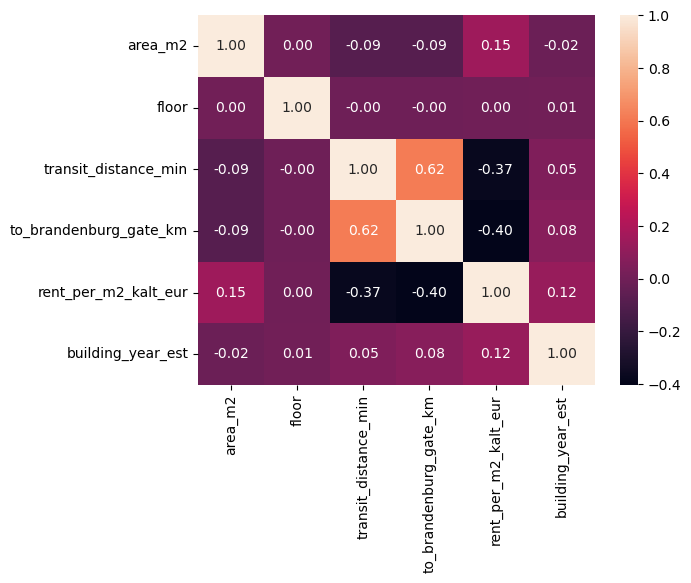

In [19]:
relevant_cols = ["area_m2", "floor", "transit_distance_min", "to_brandenburg_gate_km", "rent_per_m2_kalt_eur", "building_year_est"]

numeric_rentals = rentals[relevant_cols]

sns.heatmap(numeric_rentals.corr(), annot = True, fmt = "0.2f")
plt.show()

For the target variable `rent_per_m2_kalt_eur`, the heatmap indicates the following linear associations:

1. The strongest negative linear association among the numerical variables is observed with `to_brandenburg_gate_km`.
2. A similarly clear negative relationship exists with `transit_distance_min`.
3. weak linear relationships with `area_m2` and `building_year_est`.

### 3.3.2. Visualizing Relationships

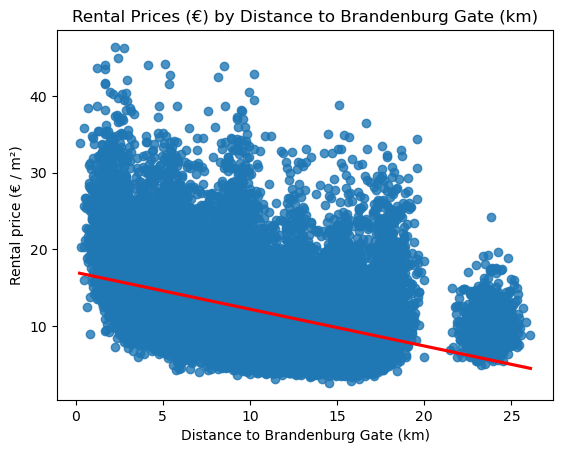

In [20]:
sns.regplot(
    data=rentals,
    x="to_brandenburg_gate_km",
    y="rent_per_m2_kalt_eur",
    line_kws = {"color" : "red"}
)
plt.title("Rental Prices (€) by Distance to Brandenburg Gate (km)")
plt.ylabel("Rental price (€ / m²)")
plt.xlabel("Distance to Brandenburg Gate (km)")
plt.show()

The scatter plot shows a moderate negative linear association between distance from the Brandenburg Gate and rental price per square metre (r=−0.40). Rental prices generally tend to decrease with increasing distance from the Brandenburg Gate. However, the large variation in rental prices at similar distances indicates that additional factors influence rental prices.

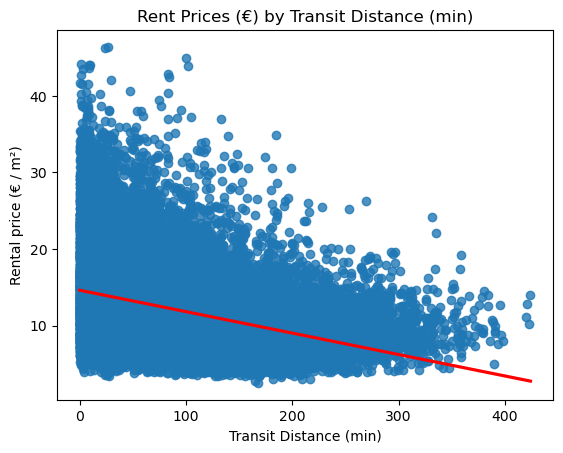

In [21]:
sns.regplot(
    data=rentals,
    x="transit_distance_min",
    y="rent_per_m2_kalt_eur",
    line_kws  ={"color" : "red"}
)
plt.title("Rent Prices (€) by Transit Distance (min)")
plt.ylabel("Rental price (€ / m²)")
plt.xlabel("Transit Distance (min)")
plt.show()

Similar to the plot above, this scatterplot also shows a moderate negative linear relationship. Rental prices tend to decrease with increased transit distance, although the relationship is slightly weaker than for distance to the Brandenburg Gate (r=-0.37).

## 3.4. Time 

As an additional analysis, we investigate whether the listing date and time are associated with rental prices.

We visualize the relationship between the listing timestamp and rental prices to identify potential temporal patterns.

In [22]:
# organizing date_listed to year-month for simplicity and better runtime

rentals['month'] = rentals['date_listed'].dt.month
rentals['year'] = rentals['date_listed'].dt.year
rentals['year_month'] = pd.to_datetime(rentals['year'].astype(str) + rentals['month'].astype(str), format='%Y%m')
rentals = rentals.drop(['month', 'year'], axis=1)

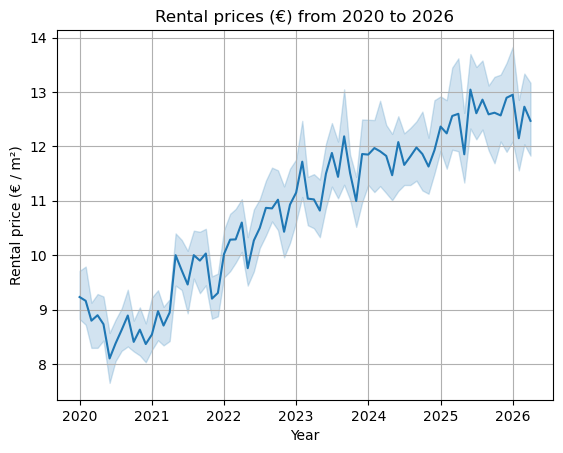

In [23]:
rent_year = sns.lineplot(x='year_month', y='rent_per_m2_kalt_eur', estimator = "median", data=rentals)
plt.grid()
rent_year.set_title('Rental prices (€) from 2020 to 2026')
plt.ylabel("Rental price (€ / m²)")
plt.xlabel("Year")
plt.show()

The line plot shows a clear upward trend in median rental prices between 2020 and 2026 indicating an association between the listing time and the rental prices.

# 4. Inferential Analysis

In this section, we further investigate selected observations made during the descriptive analysis using inferential statistical methods.

## 4.1. Hypothesis Testing for Amenities

During the descriptive analysis, we observed only minor differences in median rental prices between the different amenities. In this section, we perform Student's t-tests to assess whether the differences in mean rental prices between the groups are statistically significant.

For each amenity, we test the following hypotheses: 

$H_0$: The mean rental prices are equal between properties with and without the respective amenity

$H_1$: The mean rental prices differ between properties with and without the respective amenity

In [24]:
amenities = ["has_lift", "has_balcony", "furnished"]
results = []

for var in amenities:
    group_yes = rentals.loc[rentals[var] == True, "rent_per_m2_kalt_eur"]
    group_no  = rentals.loc[rentals[var] == False, "rent_per_m2_kalt_eur"]
    stat, p_levene = sps.levene(group_yes, group_no)
    if p_levene > 0.05:
        t_stat, p_value = sps.ttest_ind(group_yes, group_no, equal_var=True)
    else: 
        t_stat, p_value = sps.ttest_ind(group_yes, group_no, equal_var=False)

    results.append({
        "Amenity": var,
        "Mean (Yes)": group_yes.mean(),
        "Mean (No)": group_no.mean(),
        "t-statistic": t_stat,
        "p-value": p_value,
        "Levene-Test p-value": p_levene
    })

ttest_df = pd.DataFrame(results)
ttest_df

,Amenity,Mean (Yes),Mean (No),t-statistic,p-value,Levene-Test p-value
0,has_lift,12.761004,11.603369,18.033266,2.850055e-72,7.600984e-33
1,has_balcony,12.233548,11.960880,4.227270,2.372427e-05,7.373105e-02
2,furnished,12.145763,12.117749,0.355484,7.222298e-01,8.842405e-01


The results indicate that the amenities `has_lift` and `has_balcony` are associated with statistically significant differences in mean rental prices between the respective groups. In contrast, the difference for `furnished` is not statistically significant.

It should be noted that the Levene test indicates unequal variances for `has_lift`. Therefore, Welch's t-test was used, as it does not assume equal variances between the groups. 

It is also worth to mention that due to the large sample size (30.000), even minor differences can become statistically significant.

## 4.2. ANOVA

### 4.2.1. ANOVA for Districts

To determine whether the observed differences in rental prices across Berlin districts are statistically significant, we perform a one-way ANOVA. 

This allows us to test whether at least one district has a significantly different mean rental price compared to the others.

$H_0$: The mean rental prices are equal across all Berlin districts

$H_1$: At least one Berlin district has a different mean rental price.

In [25]:
groups = [group["rent_per_m2_kalt_eur"].values for name, group in rentals.groupby("bezirk")]

f_stat, p_val = sps.f_oneway(*groups)

print(f"F-statistic = {f_stat}, p-value = {p_val}")

F-statistic = 2249.572916408498, p-value = 0.0


With $p < 0.05$ we can reject $H_0$ and therefore know that there is *at least* one Berlin district with a significantly different rental price mean than the others. This confirms the observations made during the descriptive analysis.

### 4.2.2. ANOVA for Condition

As previous observations suggested little to no differences in median rental prices across different property conditions, we perform a one-way ANOVA to assess whether these differences in mean rental prices are statistically significant.

$H_0$: The mean rental prices are equal across all property conditions.

$H_1$: At least one property condition has a different mean rental price.

In [26]:
groups = [group["rent_per_m2_kalt_eur"].values for name, group in rentals.groupby("condition")]

f_stat, p_val = sps.f_oneway(*groups)

print(f"F-statistic = {f_stat}, p-value = {p_val}")

F-statistic = 2.190438905385565, p-value = 0.06736535934416771


With $p > 0.05$, we cannot reject $H_0$. Therefore, there is insufficient statistical evidence to conclude that the mean rental prices differ across property conditions. This supports the observation made during the descriptive analysis.

## 4.3. Simple and Multiple linear Regression 

In this final section, we apply simple and multiple linear regression models to investigate how individual variables and combinations of previously analyzed variables are associated with rental prices.

### 4.3.1. Simple Regression

Performing simple linear regression, we analyze the strength and statistical significance of the relationships between the previously highlighted numerical variables and rental prices.

In [27]:
numeric_predictors = ["area_m2", "to_brandenburg_gate_km", "transit_distance_min", "building_year_est"]

single_results = []

for var in numeric_predictors:
    model = smf.ols(f"rent_per_m2_kalt_eur ~ {var}", data=rentals).fit()
    single_results.append({
        "Variable": var,
        "Coefficient": model.params[var],
        "p-value": model.pvalues[var],
        "R-squared": model.rsquared
    })

single_df = pd.DataFrame(single_results)
single_df

,Variable,Coefficient,p-value,R-squared
0,area_m2,0.021674,1.118324e-146,0.021930
1,to_brandenburg_gate_km,-0.480289,0.000000e+00,0.163199
2,transit_distance_min,-0.028014,0.000000e+00,0.138511
3,building_year_est,0.023377,1.815971e-102,0.015281


For every variable, we observe $p < 0.05$, indicating that the linear relationship between each variable and rental prices is statistically significant.

However, the $R^2$ values show that location-related variables explain substantially more variance in rental prices than the structural variables `area_m2`and `building_year_est`.

### 4.3.2. Multiple Regression

Finally, we analyze the joint association of the previously selected variables with the target variable (`rent_per_m2_kalt_eur`) using multiple linear regression.

We exclude `to_brandenburg_gate_km` and `transit_distance_min` to avoid potential multicollinearity between multiple variables describing location characteristics.

In [28]:
model_multi = smf.ols(
    "rent_per_m2_kalt_eur ~ C(bezirk) + has_lift + has_balcony + building_year_est + area_m2",
    data = rentals
).fit()

print(model_multi.summary())
print("================================================================================================================")

                             OLS Regression Results                             
Dep. Variable:     rent_per_m2_kalt_eur   R-squared:                       0.490
Model:                              OLS   Adj. R-squared:                  0.490
Method:                   Least Squares   F-statistic:                     1923.
Date:                  Mon, 13 Jul 2026   Prob (F-statistic):               0.00
Time:                          19:05:32   Log-Likelihood:                -83509.
No. Observations:                 30000   AIC:                         1.671e+05
Df Residuals:                     29984   BIC:                         1.672e+05
Df Model:                            15                                         
Covariance Type:              nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

The multiple linear regression model evaluates the association between each variable and the target variable (rental prices) while keeping all other included variables constant and thus controlling their influence. This allows us to assess the individual contribution of each variable to rental prices.

The model explains approximately 49% of the variance in rental prices ($R^2=0.49$). All included variables show statistically significant associations with rental prices ($p < 0.001$). However, again due to the large sample size, statistical significance does not imply practical impact.

The coefficients indicate that location, represented by the different districts, is the most influential factor in the model. Compared to the reference district (*Charlottenburg-Wilmersdorf*), several districts show substantially different coefficients and therefore different estimated rental prices, highlighting the importance of location.

Additionally, amenities such as `has_lift` and `has_balcony` remain significantly associated with rental prices. However, their coefficients are relatively small, suggesting a limited practical effect compared to location.

The numerical variables `building_year_est` and `area_m2` also show statistically significant associations with rental prices. Nevertheless, their small coefficients indicate that their individual contribution to the rental price is rather limited.

### 4.3.3. Estimating Rental Prices in the Future (Extra)

As an additional analysis, we use the observed temporal trend in rental prices to estimate future mean rental prices for Berlin for the years 2027, 2028, and 2029.

In [29]:
rentals["year"] = rentals["date_listed"].dt.year.astype("int")

model_time = smf.ols("rent_per_m2_kalt_eur ~ year", data = rentals).fit()

future = pd.DataFrame(
    {"year" : [2026 ,2027, 2028, 2029]}
)

future = future.assign(estimate = model_time.predict(future))

observed_means = pd.DataFrame(rentals.groupby("year").agg(observed_mean = ("rent_per_m2_kalt_eur", "mean"))).reset_index()

future.merge(observed_means, on = "year", how = "outer")

,year,estimate,observed_mean
0,2020,NaN,9.686398
1,2021,NaN,10.443094
2,2022,NaN,11.796985
3,2023,NaN,12.747187
4,2024,NaN,13.291527
5,2025,NaN,14.099427
6,2026,14.935768,14.096967
7,2027,15.783858,NaN
8,2028,16.631948,NaN
9,2029,17.480038,NaN


The observed data shows an increase of approximately 1 €/m² in the mean rental price per year. Based on this trend, the linear regression model estimates a further increase of approximately 1 €/m² per year for the period from 2027 to 2029. Under this assumption, the estimated mean rental price in Berlin in 2029 is approximately 17.4 €/m².

# 5. Conclusion

This project investigated which rental characteristics and locations are associated with higher cold rent prices in Berlin, based on a dataset of 30,000 rental listings.

The descriptive analysis showed that rental prices vary considerably and are right-skewed, with a small number of high-priced listings driving the mean above the median. Location emerged as the most striking factor. Rental prices differed substantially across Berlin districts, while apartment amenities and condition showed comparatively minor differences. Additionally, an upward trend in rental prices was observed over the period from 2020 to 2026, indicating a general increase in the Berlin rental market independent of individual property characteristics.

These observations were supported by the inferential analysis. Student's and Welch's t-tests showed that `has_lift` and `has_balcony` are associated with statistically significant, although practically small, differences in rental prices, while `furnished` showed no significant effect. The first one-way ANOVA confirmed the observed significant differences in rental prices across Berlin districts (`bezirk`), while the second found no significant differences across property conditions. Simple linear regression further confirmed that location-related variables (`to_brandenburg_gate_km` and `transit_distance_min`) explain considerably more variance in rental prices ($R^2 = 14$–$16\%$) than structural variables.

Finally, the multiple linear regression model explained approximately 49% of the variance in rental prices. Combining district, amenities, building year, and area, district showed by far the largest coefficients, confirming location as the dominant factor associated with rental prices, while the remaining features contributed smaller, though still statistically significant, effects.

Overall, the analysis suggests that location is the primary factor associated with higher rental prices in Berlin, with amenities and structural characteristics playing a comparatively minor role. It is also worth noting that Berlin rental prices appear to increase over time, independent of individual property characteristics.